<div class="alert alert-info" role="alert"
     style="font-size: 1.55em; font-weight: bold; padding: 15px; margin: 10px 0; text-align: left; background-color: #d9edf7; border-color: #bce8f1; color: #31708f; border-radius: 8px;">
    CLARA May-August cloud fraction and AVHRR instrument joins
</div>

### Basic set up ▶▶ Libraries

In [1]:
import xarray as xr
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import regionmask

In [2]:
fm.fontManager.addfont("/home/nandii/cloudf/Roboto-Regular.ttf")
fm.fontManager.addfont("/home/nandii/cloudf/Roboto-Bold.ttf")
plt.rcParams["font.weight"] = "normal"
plt.rcParams["axes.titleweight"] = "bold"

### Load data ▶▶ `CLARA cfc` daily May-Aug box mean

In [3]:
bloom_months = [5, 6, 7, 8]

ds = xr.concat([xr.open_zarr("/home/nandii/cloudf/cfc_subset_1990_MJJA.zarr"),
                xr.open_zarr("/home/nandii/cloudf/cfc_subset_1991_2010.zarr"),
                xr.open_zarr("/home/nandii/cloudf/cfc_subset_2011_2026.zarr")], dim = "time").sortby("time")
# Box trimmed to 60W-20W
ds = ds.sel(lon = slice(-60, -20))

# Land mask, as in the CLARA trend notebooks
land = regionmask.defined_regions.natural_earth_v5_0_0.land_110.mask(ds.lon, ds.lat)
cf = ds["cfc"].where(np.isnan(land))
cf = cf.sel(time = cf.time.dt.month.isin(bloom_months)).mean(dim = ["lat", "lon"]).compute()
clara = pd.Series(cf.values, index = pd.DatetimeIndex(cf.time.values)).dropna()

print(f"CLARA: {len(clara)} days, {clara.index.min().date()} to {clara.index.max().date()}")

CLARA: 4516 days, 1990-05-01 to 2026-07-28


### Instrument joins ▶▶ first day each AVHRR satellite is used by CLARA

In [4]:
cross = pd.read_csv("/home/nandii/cloudML/avhrr_crossing_times_1990_2026.csv", parse_dates = ["date"], low_memory = False)

# First use of each satellite, plus any return after more than a year out of CLARA
used = cross[cross["in_clara"]].sort_values("date")
gap = used.groupby("satellite")["date"].diff().dt.days
joins = used[gap.isna() | (gap > 365)][["satellite", "date"]]
joins["label"] = np.where(gap[joins.index].isna(), joins["satellite"], joins["satellite"] + " rejoins")

# Satellites already in use when the CLARA series starts have no join inside the record
joins = joins[joins["date"] > clara.index.min()].reset_index(drop = True)
joins

,satellite,date,label
0,NOAA-12,1991-09-16,NOAA-12
1,NOAA-14,1995-01-20,NOAA-14
2,NOAA-15,1998-10-26,NOAA-15
3,NOAA-16,2001-01-01,NOAA-16
4,NOAA-17,2002-07-10,NOAA-17
5,NOAA-18,2005-06-05,NOAA-18
6,Metop-A,2007-06-28,Metop-A
7,NOAA-19,2009-02-22,NOAA-19
8,Metop-B,2013-01-01,Metop-B
9,Metop-C,2019-07-03,Metop-C


### Plot ▶▶ CLARA daily cloud fraction with instrument joins

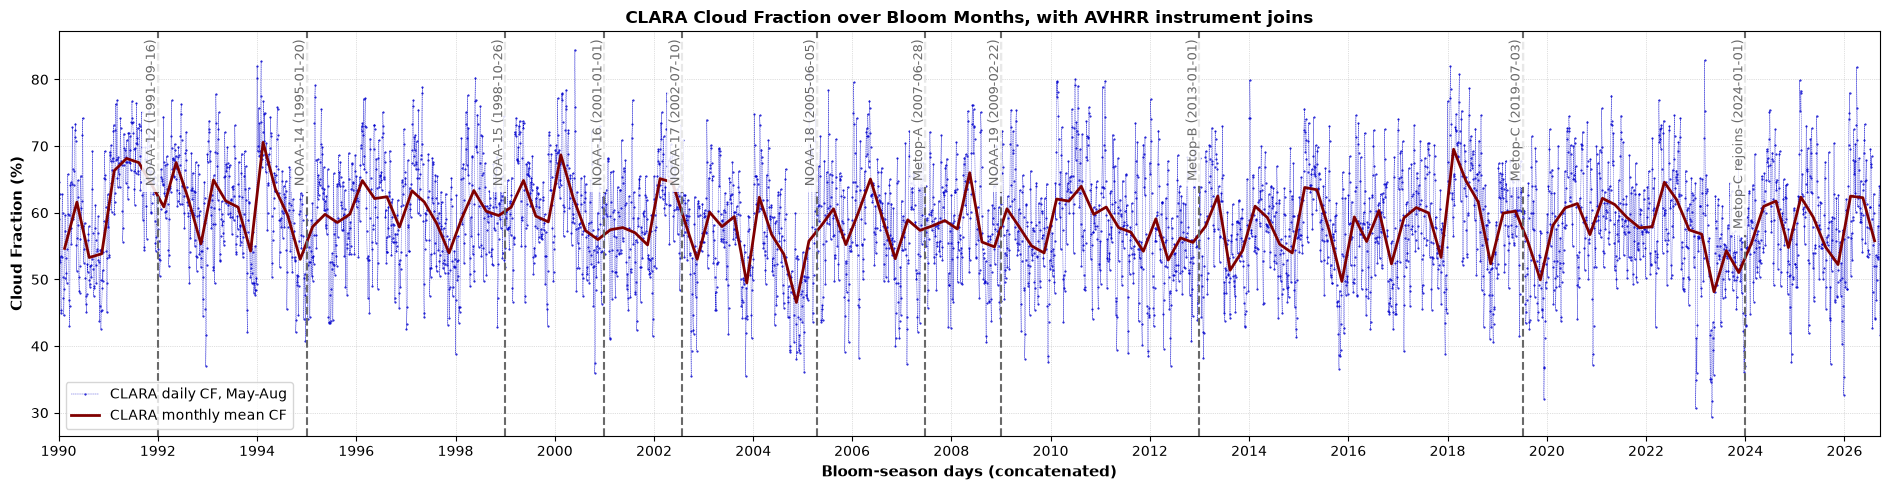

In [5]:
# Concatenated May-Aug axis; a join outside May-Aug is drawn at the next bloom-season day
seq = pd.Series(range(len(clara)), index = clara.index)
joins = joins[joins["date"] <= clara.index.max()]
joins["x"] = [seq[seq.index >= d].iloc[0] for d in joins["date"]]
first_days = seq.groupby(seq.index.year).min()

# Monthly means, placed at the mean position of their days on the concatenated axis
monthly = pd.DataFrame({"seq": seq, "cfc": clara}).groupby(clara.index.to_period("M")).mean()

fig, ax = plt.subplots(figsize = (19, 5))
ax.plot(seq.values, clara.values, linewidth = 0.25, linestyle = '--', marker = '.', markersize = 1,
        color = 'mediumblue', label = 'CLARA daily CF, May-Aug')
ax.plot(monthly["seq"], monthly["cfc"], linewidth = 2.0, color = 'maroon', label = 'CLARA monthly mean CF')

for _, j in joins.iterrows():
    ax.axvline(j["x"], color = 'dimgrey', linestyle = '--', linewidth = 1.5)
    ax.text(j["x"], 0.98, f" {j['label']} ({j['date']:%Y-%m-%d})", transform = ax.get_xaxis_transform(),
            rotation = 90, va = 'top', ha = 'right', fontsize = 9, color = 'dimgrey',
            bbox = dict(facecolor = 'white', edgecolor = 'none', alpha = 0.85, pad = 1))

ax.set_xticks(first_days.values[::2])
ax.set_xticklabels(first_days.index[::2])
ax.margins(x = 0)
ax.set_xlabel('Bloom-season days (concatenated)', fontsize = 11, weight = 'bold')
ax.set_ylabel('Cloud Fraction (%)', fontsize = 11, weight = 'bold')
ax.set_title('CLARA Cloud Fraction over Bloom Months, with AVHRR instrument joins', fontsize = 12, weight = 'bold')
ax.grid(True, color = 'silver', linestyle = ':', linewidth = 0.5)
ax.legend(loc = 'lower left')
plt.tight_layout()
plt.show()

In [6]:
fig.savefig('CLARA_instrument_joins.png', dpi = 300, bbox_inches = 'tight')